# Project 1: VaR and ES -- Estimation, Backtesting, and Model Comparison

**Names of all group members:**
- Firstname Lastname (email@example.com)
- Firstname Lastname (email@example.com)

---

## 0) Setup

Creates necessary folders, sets parameters, and fixes the random seed. Keep this seed fixed; the whole run must be reproducible from it.

In [19]:
# If a package import fails, install it in your environment, e.g.:
# %pip install arch statsmodels

import os
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path.cwd()
DATA_FILE = PROJECT_DIR / "../data/QRM_2026_Project_prices.csv"   # provided with the project; do not re-download
OUT_DIR = PROJECT_DIR / "../output"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Parameters
TICKERS = ["AAPL", "META", "JPM"]   # every question is run separately on each stock
WINDOW = 504                        # estimation window of every model, in trading days (Questions 2-5)
EVAL_START = 504                    # Questions 3-5: forecast days are all days after the first 504
REFIT = 21                          # Questions 4-5: re-estimate every this many trading days
ALPHAS = [0.975, 0.99]              # confidence levels used throughout Questions 2-5
DEEP_ALPHA = 0.999                  # Question 6: the extreme level EVT is asked for
M_SIM = 10_000                      # Questions 3(c), 4(d): Acerbi-Szekely simulated samples
LB_LAGS = 10                        # Ljung-Box H in Questions 1 and 4
NW_LAGS = 10                        # Newey-West truncation lag of the Diebold-Mariano test
SEED = 0                            # fix this, state it in the report, do not change it later

rng = np.random.default_rng(SEED)
print("Project dir:", PROJECT_DIR)


Project dir: c:\Users\msaco\Documents\M2\epfl\MA3\qrm\QRM_Project\src


## 1) Data

The prices were downloaded once with `yfinance` (adjusted closes, 2 January 2013 to 30 June 2026,
downloaded on 28 October 2026) and are provided as `QRM_2026_Project_prices.csv`. Read this file;
do not download the data again, since Yahoo revises adjusted prices back in time.

In [20]:
price_df = pd.read_csv(DATA_FILE, index_col=0, parse_dates=True)[TICKERS]
print(price_df.shape, price_df.index[0].date(), "to", price_df.index[-1].date())   # (3393, 3)

(3393, 3) 2013-01-02 to 2026-06-30


## 2) Log-returns and losses

Construct $R_t=\log(P_t/P_{t-1})$ for each ticker. The log-loss used everywhere in this project is
$L_t=-R_t$. Every question is run separately on each of the three columns; there is no portfolio.

In [21]:
returns = np.log(price_df / price_df.shift(1)).dropna()
losses = -returns

print(returns.shape, returns.index[0].date(), "to", returns.index[-1].date())   # (3392, 3)
returns.head()

(3392, 3) 2013-01-03 to 2026-06-30


,AAPL,META,JPM
Date,,,
2013-01-03,-0.012703,-0.008248,-0.002017
2013-01-04,-0.028250,0.035029,0.017569
2013-01-07,-0.005900,0.022689,0.001101
2013-01-08,0.002688,-0.012312,0.001980
2013-01-09,-0.015752,0.051311,-0.000660


## Question 1 -- Stylized facts

For each stock: (a) plot the return series; (b) ACF of returns and of squared returns, and the
Ljung-Box test with $H$ = `LB_LAGS` on both (`statsmodels.stats.diagnostic.acorr_ljungbox`);
(c) QQ-plot and Jarque-Bera.

### Question 1 (a)
Report section 1.1, Figure 1 (a) and Table 1

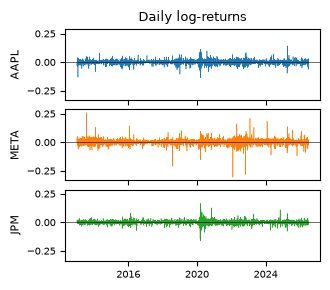

Correlation of 21-day rolling volatilities:
       AAPL  META   JPM
AAPL  1.00  0.56  0.66
META  0.56  1.00  0.43
JPM   0.66  0.43  1.00

Correlation of daily returns:
       AAPL  META   JPM
AAPL  1.00  0.46  0.39
META  0.46  1.00  0.31
JPM   0.39  0.31  1.00

Top-5 largest moves of AAPL (in %, all three stocks that day):
             AAPL   META    JPM
Date                           
2025-04-09  14.26  13.76   7.75
2020-03-16 -13.77 -15.38 -16.21
2013-01-24 -13.19   0.84   0.30
2020-03-13  11.32   9.74  16.56
2019-01-03 -10.49  -2.95  -1.43

Top-5 largest moves of META (in %, all three stocks that day):
            AAPL   META   JPM
Date                         
2022-02-03 -1.69 -30.64 -0.83
2022-10-27 -3.09 -28.18  0.39
2013-07-25 -0.46  25.94 -0.23
2018-07-26 -0.31 -21.02 -0.29
2023-02-02  3.64  20.93 -0.47

Top-5 largest moves of JPM (in %, all three stocks that day):
             AAPL   META    JPM
Date                           
2020-03-13  11.32   9.74  16.56
2020-03-16 -13.77 

In [22]:
# Question 1
# (a)
import matplotlib.dates as mdates

colors = {"AAPL": "tab:blue", "META": "tab:orange", "JPM": "tab:green"}

fig, axes = plt.subplots(3, 1, figsize=(3.4, 3), sharex=True, sharey=True)
for ax, tic in zip(axes, TICKERS):
    ax.plot(returns.index, returns[tic], lw=0.4, color=colors[tic])
    ax.axhline(0, color="black", lw=0.4)
    ax.set_ylabel(tic, fontsize=8)
    ax.tick_params(labelsize=7)
axes[-1].xaxis.set_major_locator(mdates.YearLocator(4))   
axes[0].set_title("Daily log-returns", fontsize=9)
plt.tight_layout(h_pad=0.3)
plt.savefig(OUT_DIR / "fig_q1a_returns.png", dpi=200)
plt.show()

roll_vol = returns.rolling(21).std() * np.sqrt(252)         
print("Correlation of 21-day rolling volatilities:\n", roll_vol.corr().round(2))
print("\nCorrelation of daily returns:\n", returns.corr().round(2))
for tic in TICKERS:                                          
    top = returns[tic].abs().nlargest(5).index
    print(f"\nTop-5 largest moves of {tic} (in %, all three stocks that day):")
    print((100 * returns.loc[top]).round(2).to_string())

Question 1 (a) volatility part

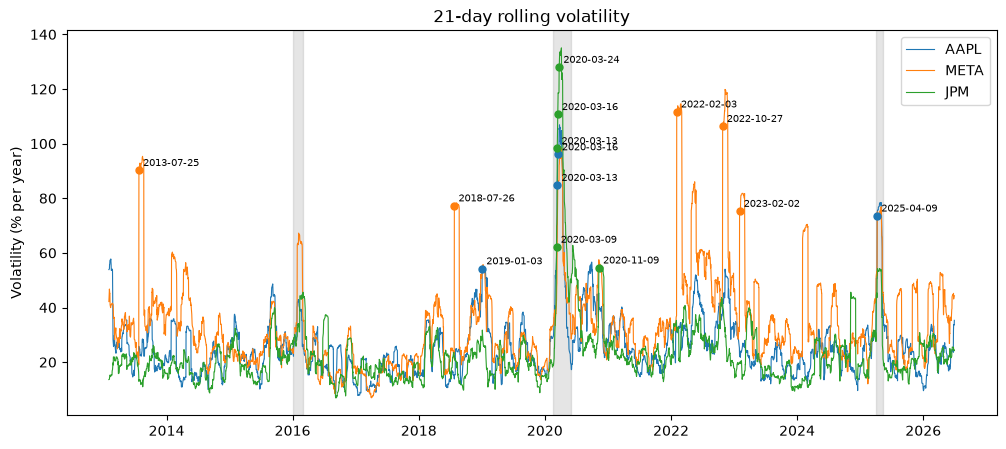

In [23]:
# Question 1 (a) 

vol = returns.rolling(21).std() * np.sqrt(252) * 100
colors = {"AAPL": "tab:blue", "META": "tab:orange", "JPM": "tab:green"}

plt.figure(figsize=(12, 5))

plt.axvspan(pd.Timestamp("2016-01-01"), pd.Timestamp("2016-02-29"), color="grey", alpha=0.2)
plt.axvspan(pd.Timestamp("2020-02-20"), pd.Timestamp("2020-05-31"), color="grey", alpha=0.2)
plt.axvspan(pd.Timestamp("2025-04-01"), pd.Timestamp("2025-05-15"), color="grey", alpha=0.2)

for tic in TICKERS:
    #The volatility curve
    plt.plot(vol.index, vol[tic], label=tic, lw=0.8, color=colors[tic])

    #The 5 days with the largest move (in absolute value)
    big_days = returns[tic].abs().sort_values(ascending=False).head(5).index
    for day in big_days:
        plt.scatter(day, vol.loc[day, tic], color=colors[tic], s=25, zorder=3)
        plt.annotate(day.strftime("%Y-%m-%d"), (day, vol.loc[day, tic]),
                     fontsize=7, xytext=(3, 3), textcoords="offset points")

plt.ylabel("Volatility (% per year)")
plt.title("21-day rolling volatility")
plt.legend()
plt.savefig(OUT_DIR / "fig_q1a_vol.png", dpi=200)
plt.show()

Report section 1.1, Figure 1 (b)

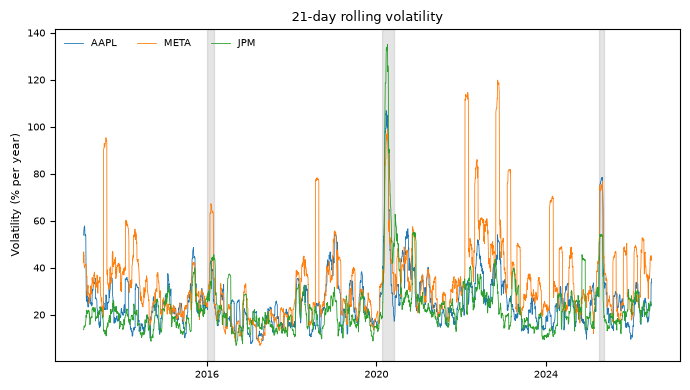

In [24]:
# Question 1 (a)
import matplotlib.dates as mdates

vol = returns.rolling(21).std() * np.sqrt(252) * 100
colors = {"AAPL": "tab:blue", "META": "tab:orange", "JPM": "tab:green"}

plt.figure(figsize=(7, 4))

plt.axvspan(pd.Timestamp("2016-01-01"), pd.Timestamp("2016-02-29"), color="grey", alpha=0.2)
plt.axvspan(pd.Timestamp("2020-02-20"), pd.Timestamp("2020-05-31"), color="grey", alpha=0.2)
plt.axvspan(pd.Timestamp("2025-04-01"), pd.Timestamp("2025-05-15"), color="grey", alpha=0.2)

for tic in TICKERS:
    plt.plot(vol.index, vol[tic], label=tic, lw=0.6, color=colors[tic])

plt.gca().xaxis.set_major_locator(mdates.YearLocator(4))
plt.tick_params(labelsize=7)
plt.ylabel("Volatility (% per year)", fontsize=8)
plt.title("21-day rolling volatility", fontsize=9)
plt.legend(fontsize=7, frameon=False, loc="upper left", ncol=3)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig_q1a_vol.png", dpi=200)
plt.show()

Numbers of section 1.1

In [25]:
# Question 1 (a): peak 21-day rolling volatility (annualised, %) in March 2020
vol = returns.rolling(21).std() * np.sqrt(252) * 100
v = vol.loc["2020-02-20":"2020-05-31"]
print(pd.DataFrame({"peak vol (%)": v.max(), "date of peak": v.idxmax().dt.date}).round(1))

      peak vol (%) date of peak
AAPL         106.9   2020-03-26
META          98.4   2020-04-06
JPM          135.1   2020-04-06


### Question 1 (b)
Report section 1.2, figure 2 and Table 2

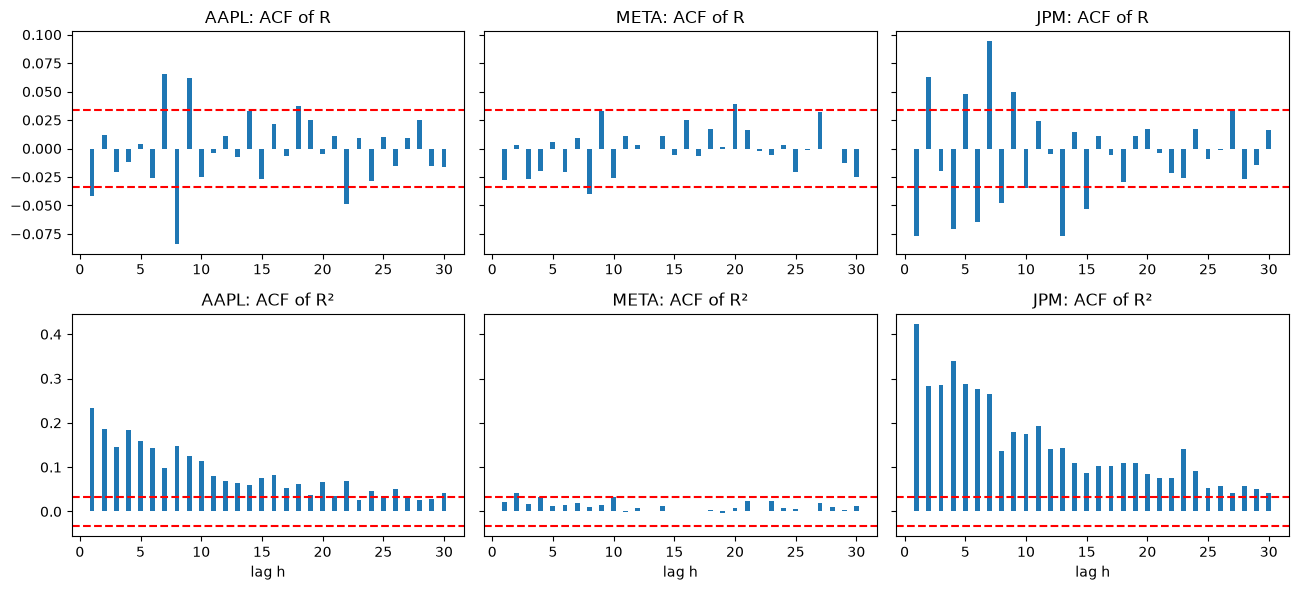

Ljung-Box test results
          Q (R)  p-value (R)     Q (R²)  p-value (R²)
stock                                                
AAPL    64.4300       0.0000   849.2934         0.000
META    19.5762       0.0335    19.0975         0.039
JPM    124.2931       0.0000  2607.4927         0.000


In [26]:
# Question 1 (b) 
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox

n = len(returns)
band = 1.96 / np.sqrt(n)          # 95% band if the data were i.i.d.
lags = range(1, 31)               # lags 1, 2, ..., 30

fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey="row")

for i, tic in enumerate(TICKERS):
    r = returns[tic]
    r2 = r ** 2

    # ACF of the returns
    acf_r = acf(r, nlags=30)[1:]          # [1:] removes lag 0 (always 1)
    axes[0, i].bar(lags, acf_r, width=0.4)
    axes[0, i].axhline(band, color="red", ls="--")
    axes[0, i].axhline(-band, color="red", ls="--")
    axes[0, i].set_title(f"{tic}: ACF of R")

    # ACF of the squared returns
    acf_r2 = acf(r2, nlags=30)[1:]
    axes[1, i].bar(lags, acf_r2, width=0.4)
    axes[1, i].axhline(band, color="red", ls="--")
    axes[1, i].axhline(-band, color="red", ls="--")
    axes[1, i].set_title(f"{tic}: ACF of R²")
    axes[1, i].set_xlabel("lag h")

plt.tight_layout()
plt.savefig(OUT_DIR / "fig_q1b_acf.png", dpi=200)
plt.show()

# Ljung-Box test with H = 10
print("Ljung-Box test results")
results = []
for tic in TICKERS:
    r = returns[tic]
    lb_r = acorr_ljungbox(r, lags=[LB_LAGS])
    lb_r2 = acorr_ljungbox(r ** 2, lags=[LB_LAGS])
    results.append({"stock": tic,
                    "Q (R)": lb_r["lb_stat"].iloc[0],
                    "p-value (R)": lb_r["lb_pvalue"].iloc[0],
                    "Q (R²)": lb_r2["lb_stat"].iloc[0],
                    "p-value (R²)": lb_r2["lb_pvalue"].iloc[0]})

lb_table = pd.DataFrame(results).set_index("stock")
print(lb_table.round(4))

### Question 1 (c)
Report section 1.3, figure 3 and table 3

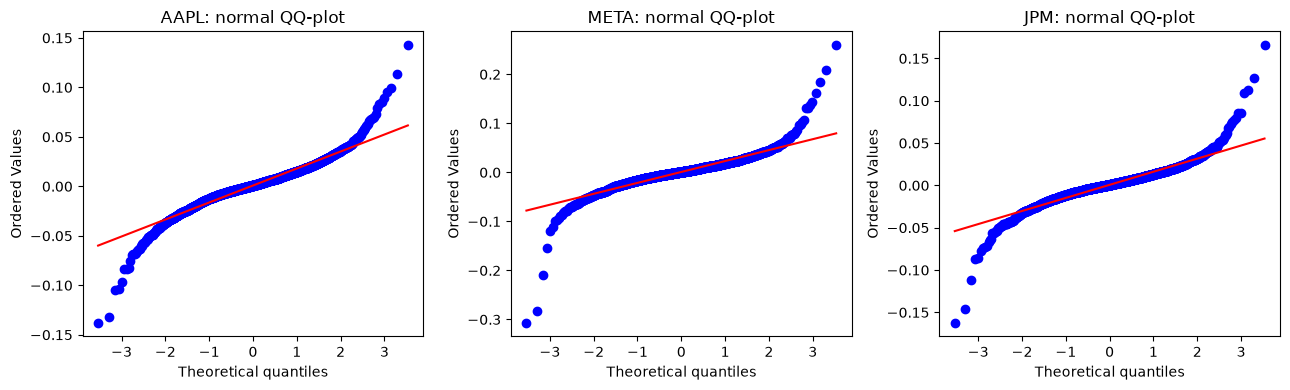

       skewness  kurtosis          JB  p-value
stock                                         
AAPL    -0.2247    9.8139   6590.6140      0.0
META    -0.4974   27.3901  84216.0510      0.0
JPM     -0.0843   15.9363  23655.8191      0.0


In [27]:
# Question 1 (c) 

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for i, tic in enumerate(TICKERS):
    r = returns[tic]
    stats.probplot(r, dist="norm", plot=axes[i])   # QQ-plot against the normal
    axes[i].set_title(f"{tic}: normal QQ-plot")

plt.tight_layout()
plt.savefig(OUT_DIR / "fig_q1c_qq.png", dpi=200)
plt.show()

# Jarque-Bera test + skewness and kurtosis
results = []
for tic in TICKERS:
    r = returns[tic]
    jb_stat, jb_pvalue = stats.jarque_bera(r)
    results.append({"stock": tic,
                    "skewness": stats.skew(r),
                    "kurtosis": stats.kurtosis(r, fisher=False),   # normal = 3
                    "JB": jb_stat,
                    "p-value": jb_pvalue})

jb_table = pd.DataFrame(results).set_index("stock")
print(jb_table.round(4))

## Question 2 -- Single-window VaR and ES estimates

For each stock, use the first `WINDOW` losses as the single estimation window for (a)-(d).

### Question 2 (a)

In [28]:
# Question 2
window_loss = losses.iloc[:WINDOW]          # one column per stock
W = len(window_loss)                        
print("Window:", window_loss.index[0].date(), "to", window_loss.index[-1].date())


# Historical simulation
def hs_var_es(L, alpha):
    L_sorted = np.sort(L)[::-1]                 # largest loss first
    k = int(np.floor(W * (1 - alpha)))         
    var = L_sorted[k]                           
    es = (L_sorted[:k].sum() + (W * (1 - alpha) - k) * L_sorted[k]) / (W * (1 - alpha))
    return var, es

Window: 2013-01-03 to 2015-01-02


### Question 2 (b)

In [29]:
# Gaussian 
def normal_var_es(mu, sigma, alpha):
    z = stats.norm.ppf(alpha)                  
    var = mu + sigma * z
    es = mu + sigma * stats.norm.pdf(z) / (1 - alpha)
    return var, es

### Question 2 (c)

In [30]:
# Student-t
def t_var_es(nu, mu, sigma, alpha):
    q = stats.t.ppf(alpha, nu)                  # quantile of the standard t_nu
    var = mu + sigma * q
    es = mu + sigma * stats.t.pdf(q, nu) / (1 - alpha) * (nu + q**2) / (nu - 1)
    return var, es


def fit_t(L):
    """ML fit of (nu, mu, sigma) from several starting values of nu; keep the best."""
    best = None
    for nu_start in [2.5, 4, 6, 10, 30]:
        nu, mu, sigma = stats.t.fit(L, nu_start, loc=np.median(L), scale=np.std(L))
        loglik = stats.t.logpdf(L, nu, mu, sigma).sum()
        if best is None or loglik > best[3]:
            best = (nu, mu, sigma, loglik)
    return best

### Question 2 a-b-c
section 2 tables 4 and 5

In [31]:
# Compute VaR and ES for every alpha and with every method
rows = []        # VaR / ES results
params = {}      # fitted parameters

for tic in TICKERS:
    L = window_loss[tic].values

    mu_n = L.mean()
    sigma_n = L.std(ddof=1)
    nu, mu_t, sigma_t, loglik = fit_t(L)
    params[tic] = {"mu_n": mu_n, "sigma_n": sigma_n,
                   "nu": nu, "mu_t": mu_t, "sigma_t": sigma_t}

    for alpha in ALPHAS:
        var, es = hs_var_es(L, alpha)
        rows.append({"stock": tic, "alpha": alpha, "method": "HS", "VaR": var, "ES": es})
        var, es = normal_var_es(mu_n, sigma_n, alpha)
        rows.append({"stock": tic, "alpha": alpha, "method": "Gaussian", "VaR": var, "ES": es})
        var, es = t_var_es(nu, mu_t, sigma_t, alpha)
        rows.append({"stock": tic, "alpha": alpha, "method": "Student-t", "VaR": var, "ES": es})

q2 = pd.DataFrame(rows)

# Fitted parameters
param_table = pd.DataFrame(params).T
param_table["sd_t"] = param_table["sigma_t"] * np.sqrt(param_table["nu"] / (param_table["nu"] - 2))
print("\nFitted parameters:")
print(param_table.round(4))

# VaR and ES tables, in %, the three stocks side by side
print("\nVaR (%):")
print((100 * q2.pivot_table(index=["alpha", "method"], columns="stock", values="VaR")[TICKERS]).round(2))
print("\nES (%):")
print((100 * q2.pivot_table(index=["alpha", "method"], columns="stock", values="ES")[TICKERS]).round(2))



Fitted parameters:
        mu_n  sigma_n      nu    mu_t  sigma_t    sd_t
AAPL -0.0007   0.0160  4.1324 -0.0011   0.0111  0.0155
META -0.0020   0.0251  4.6793 -0.0013   0.0178  0.0235
JPM  -0.0008   0.0116  6.4827 -0.0010   0.0097  0.0117

VaR (%):
stock            AAPL  META   JPM
alpha method                     
0.975 Gaussian   3.07  4.72  2.20
      HS         2.90  4.23  2.38
      Student-t  2.95  4.54  2.24
0.990 Gaussian   3.65  5.64  2.62
      HS         3.89  5.35  2.78
      Student-t  3.99  6.03  2.89

ES (%):
stock            AAPL  META   JPM
alpha method                     
0.975 Gaussian   3.67  5.67  2.64
      HS         4.97  5.60  2.92
      Student-t  4.25  6.35  2.99
0.990 Gaussian   4.20  6.49  3.02
      HS         7.39  6.53  3.54
      Student-t  5.56  8.14  3.69


### Question 2 (d)
section 2 figure 4

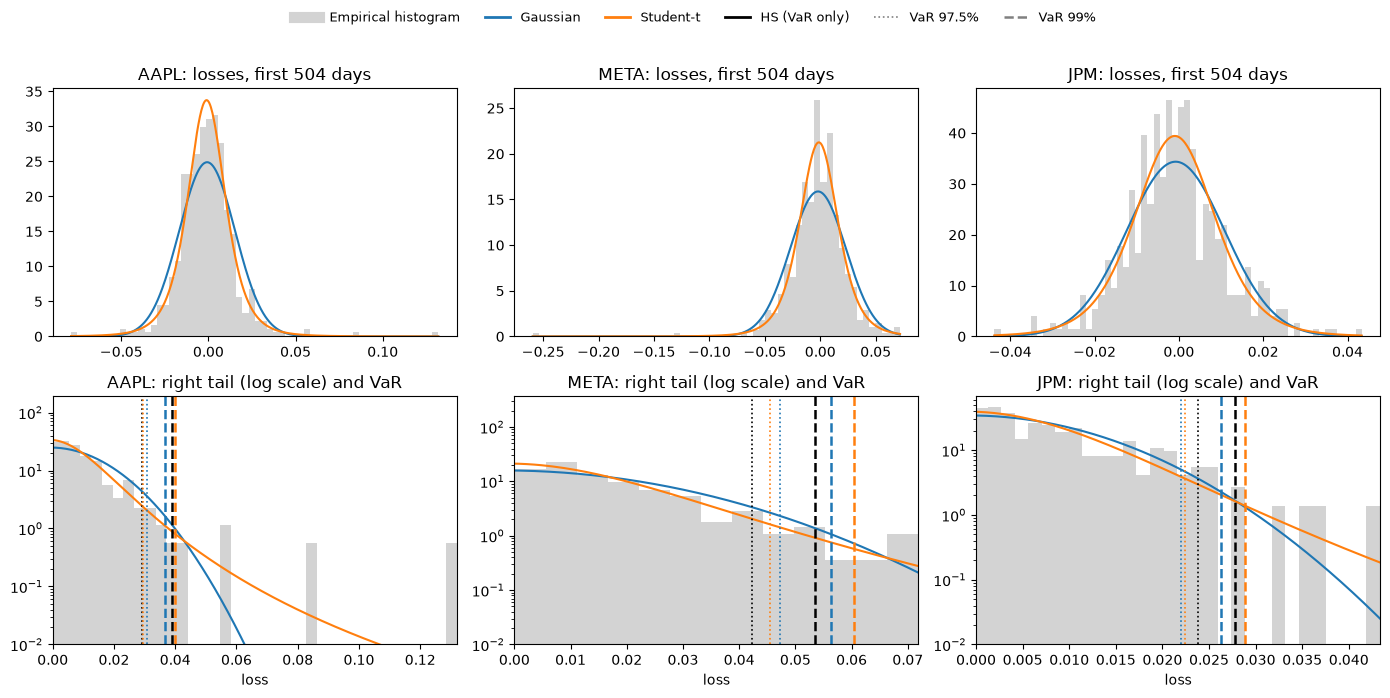

In [32]:
# Question 2 (d)
from matplotlib.lines import Line2D

colors = {"HS": "black", "Gaussian": "tab:blue", "Student-t": "tab:orange"}
styles = {0.975: (":", 1.2),      # dotted, thin
          0.99: ("--", 1.8)}      # dashed, thick

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for i, tic in enumerate(TICKERS):
    L = window_loss[tic].values
    p = params[tic]
    x = np.linspace(L.min(), L.max(), 500)

    for row in [0, 1]:
        ax = axes[row, i]
        ax.hist(L, bins=60, density=True, color="lightgrey")
        ax.plot(x, stats.norm.pdf(x, p["mu_n"], p["sigma_n"]), color=colors["Gaussian"], lw=1.5)
        ax.plot(x, stats.t.pdf(x, p["nu"], p["mu_t"], p["sigma_t"]), color=colors["Student-t"], lw=1.5)

        # VaR lines only on the tail zoom (bottom row)
        if row == 1:
            for alpha_lvl, (style, width) in styles.items():
                for method in ["HS", "Gaussian", "Student-t"]:
                    v = q2[(q2.stock == tic) & (q2.alpha == alpha_lvl) & (q2.method == method)]["VaR"].iloc[0]
                    ax.axvline(v, color=colors[method], ls=style, lw=width)

    axes[0, i].set_title(f"{tic}: losses, first {W} days")
    axes[1, i].set_yscale("log")
    axes[1, i].set_xlim(0, L.max())
    axes[1, i].set_ylim(1e-2, None)
    axes[1, i].set_title(f"{tic}: right tail (log scale) and VaR")
    axes[1, i].set_xlabel("loss")

# Legend: colour = method, line style = level
legend_items = [
    Line2D([0], [0], color="lightgrey", lw=8, label="Empirical histogram"),
    Line2D([0], [0], color=colors["Gaussian"], lw=2, label="Gaussian"),
    Line2D([0], [0], color=colors["Student-t"], lw=2, label="Student-t"),
    Line2D([0], [0], color=colors["HS"], lw=2, label="HS (VaR only)"),
    Line2D([0], [0], color="grey", ls=":", lw=1.2, label="VaR 97.5%"),
    Line2D([0], [0], color="grey", ls="--", lw=1.8, label="VaR 99%"),
]
fig.legend(handles=legend_items, loc="upper center", ncol=6, fontsize=9, frameon=False)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig(OUT_DIR / "fig_q2_densities.png", dpi=200)
plt.show()

## Question 3 -- Backtesting

### Step 1: rolling VaR/ES forecasts (HS, Gaussian, Student-$t$)
One forecast per day of the evaluation period from the `WINDOW` previous losses.

**Used in the report:** Section 3, first paragraph (check against Table 5 of Question 2, median and range of the rolling $\hat\nu$).

In [33]:
# Question 3
eval_loss = losses.iloc[EVAL_START:]        # one column per stock, 2888 forecast days
backtest_rows = []                          # dicts: stock, method, alpha, x, expected, hit, p_uc, p_ind, p_cc, pinball_bp
es_rows = []                                # dicts: stock, method, Z, p_Z, FZ

In [34]:
# Question 3, step 1: rolling one-day-ahead VaR/ES forecasts
# The forecast for day i uses the WINDOW losses before it, i.e. data up to day i-1 only.
fc = {}   # fc[tic]: one row per forecast day, fitted parameters + VaR/ES of each method and level

for tic in TICKERS:
    loss = losses[tic]
    nu, mu_t, sigma_t, _ = fit_t(loss.iloc[:WINDOW].values)   # multi-start fit on the first window only
    rows = []
    for i in range(EVAL_START, len(loss)):
        window = loss.iloc[i - WINDOW:i].values
        mu_n, sigma_n = window.mean(), window.std(ddof=1)
        # start the t fit from yesterday's estimates: one fit per day, avoids local optima
        nu, mu_t, sigma_t = stats.t.fit(window, nu, loc=mu_t, scale=sigma_t)

        row = {"mu_n": mu_n, "sigma_n": sigma_n, "nu": nu, "mu_t": mu_t, "sigma_t": sigma_t}
        for alpha in ALPHAS:
            row[f"HS_VaR_{alpha}"], row[f"HS_ES_{alpha}"] = hs_var_es(window, alpha)
            row[f"Gaussian_VaR_{alpha}"], row[f"Gaussian_ES_{alpha}"] = normal_var_es(mu_n, sigma_n, alpha)
            row[f"Student-t_VaR_{alpha}"], row[f"Student-t_ES_{alpha}"] = t_var_es(nu, mu_t, sigma_t, alpha)
        rows.append(row)
    fc[tic] = pd.DataFrame(rows, index=loss.index[EVAL_START:])

# Check: the first forecast uses the Question 2 window, so it should reproduce the Question 2 table
print(fc["AAPL"].iloc[0].filter(like="VaR"))
print(q2[q2.stock == "AAPL"][["alpha", "method", "VaR"]])

# Fitted Student-t degrees of freedom over the evaluation period
print("\nRolling Student-t nu:")
print(pd.DataFrame({tic: fc[tic]["nu"].describe() for tic in TICKERS}).round(2))


HS_VaR_0.975           0.029007
Gaussian_VaR_0.975     0.030675
Student-t_VaR_0.975    0.029466
HS_VaR_0.99            0.038878
Gaussian_VaR_0.99      0.036549
Student-t_VaR_0.99     0.039929
Name: 2015-01-05 00:00:00, dtype: float64
   alpha     method       VaR
0  0.975         HS  0.029007
1  0.975   Gaussian  0.030675
2  0.975  Student-t  0.029466
3  0.990         HS  0.038878
4  0.990   Gaussian  0.036549
5  0.990  Student-t  0.039929

Rolling Student-t nu:
          AAPL     META      JPM
count  2888.00  2888.00  2888.00
mean      4.01     3.48     3.96
std       1.58     0.55     1.59
min       2.33     2.55     1.86
25%       2.93     3.06     2.86
50%       3.25     3.34     3.55
75%       4.54     3.84     4.60
max      11.69     5.04     9.87


### Question 3(a)-(b): Kupiec, Christoffersen and pinball loss

**Used in the report:** HS, Gaussian and Student-$t$ rows of Tables 17 and 18 (combined VaR backtests, Appendix A); all numbers in Section 3.2.

In [35]:
# Question 3, step 2: VaR backtests (Kupiec, Christoffersen, pinball loss)
from scipy.special import xlogy   # xlogy(a, b) = a * log(b), with 0 * log(0) = 0 (e.g. no consecutive exceptions)


def LR_uc(x, n, p0):
    """Kupiec unconditional coverage LR statistic, chi2(1) under H0."""
    p = x / n
    return 2 * (xlogy(x, p / p0) + xlogy(n - x, (1 - p) / (1 - p0)))


def transitions(I):
    I = np.array(I)
    prev, curr = I[:-1], I[1:]
    n00 = np.sum((prev == 0) & (curr == 0))
    n01 = np.sum((prev == 0) & (curr == 1))
    n10 = np.sum((prev == 1) & (curr == 0))
    n11 = np.sum((prev == 1) & (curr == 1))
    return n00, n01, n10, n11


def LR_ind(I):
    """Christoffersen independence LR statistic, chi2(1) under H0."""
    n00, n01, n10, n11 = transitions(I)
    p01 = n01 / (n00 + n01)
    p11 = n11 / (n10 + n11)
    p = (n01 + n11) / (n00 + n01 + n10 + n11)
    l0 = xlogy(n01 + n11, p) + xlogy(n00 + n10, 1 - p)
    l1 = xlogy(n01, p01) + xlogy(n00, 1 - p01) + xlogy(n11, p11) + xlogy(n10, 1 - p11)
    return -2 * (l0 - l1)


def pinball(v, L, alpha):
    """Daily pinball loss of VaR forecasts v for realized losses L (Appendix A.1)."""
    return ((L <= v) - alpha) * (v - L)


def var_backtest(L, v, alpha):
    """All VaR backtest columns for one series of forecasts v against realized losses L."""
    I = (L > v).astype(int)
    n, x = len(I), I.sum()
    lr_uc, lr_ind = LR_uc(x, n, 1 - alpha), LR_ind(I)
    return {"x": x, "expected": n * (1 - alpha), "hit": x / n,
            "p_uc": stats.chi2.sf(lr_uc, 1),
            "p_ind": stats.chi2.sf(lr_ind, 1),
            "p_cc": stats.chi2.sf(lr_uc + lr_ind, 2),
            "pinball_bp": 1e4 * pinball(v, L, alpha).mean()}


for tic in TICKERS:
    for method in ["HS", "Gaussian", "Student-t"]:
        for alpha in ALPHAS:
            v = fc[tic][f"{method}_VaR_{alpha}"]
            backtest_rows.append({"stock": tic, "method": method, "alpha": alpha,
                                  **var_backtest(eval_loss[tic], v, alpha)})

var_table = pd.DataFrame(backtest_rows).set_index(["alpha", "stock", "method"]).sort_index()
for alpha in ALPHAS:
    print(f"\nVaR backtests, alpha = {alpha}")
    print(var_table.loc[alpha].round(3))


VaR backtests, alpha = 0.975
                   x  expected    hit   p_uc  p_ind   p_cc  pinball_bp
stock method                                                          
AAPL  Gaussian   105      72.2  0.036  0.000  0.000  0.000      13.748
      HS          86      72.2  0.030  0.110  0.004  0.005      13.601
      Student-t  103      72.2  0.036  0.001  0.000  0.000      13.716
JPM   Gaussian    95      72.2  0.033  0.009  0.000  0.000      13.207
      HS          83      72.2  0.029  0.208  0.000  0.000      13.023
      Student-t   92      72.2  0.032  0.023  0.000  0.000      13.303
META  Gaussian    78      72.2  0.027  0.495  0.000  0.001      18.321
      HS          75      72.2  0.026  0.740  0.016  0.051      18.262
      Student-t   89      72.2  0.031  0.053  0.000  0.000      18.285

VaR backtests, alpha = 0.99
                  x  expected    hit   p_uc  p_ind   p_cc  pinball_bp
stock method                                                         
AAPL  Gaussian   62 

### Question 3(c): Acerbi-Szekely Z test at $\alpha = 0.975$

**Used in the report:** Table 6 ($Z$, $p$-value, frequency and severity, Section 3.3); $Z$ and $p$-value columns of Table 19 (ES backtests, Appendix A); null mean and standard deviation of $Z$ in Section 3.3.

In [36]:
# Question 3(c): Acerbi-Szekely Z test of the ES forecasts at alpha = 0.975 (Appendix A.2)
ALPHA_ES = 0.975


def draw_losses(tic, method, i, M):
    """M losses from the forecast distribution of forecast day i (0 = first day of eval_loss)."""
    p = fc[tic].iloc[i]
    if method == "HS":                                  # resample that day's estimation window
        j = EVAL_START + i
        return rng.choice(losses[tic].values[j - WINDOW:j], M)
    if method == "Gaussian":
        return rng.normal(p["mu_n"], p["sigma_n"], M)
    if method == "Student-t":
        return p["mu_t"] + p["sigma_t"] * rng.standard_t(p["nu"], M)
    # Question 4 GARCH models: L = -(mu + sigma * Z), Z with mean 0 and variance 1
    mu, sigma = p[f"{method}_mu"], p[f"{method}_sigma"]
    if method == "Gaussian GARCH":
        return -mu + sigma * rng.standard_normal(M)
    nu = p[f"{method}_nu"]                              # Student-t GARCH: unit-variance t
    return -mu + sigma * np.sqrt((nu - 2) / nu) * rng.standard_t(nu, M)


def as_test(tic, method, alpha=ALPHA_ES, M=M_SIM):
    """Observed Z, its one-sided simulated p-value (each day's forecasts held fixed),
    the split 1 + Z = freq x sev, and the mean / sd of the simulated null distribution."""
    L = eval_loss[tic].values
    v = fc[tic][f"{method}_VaR_{alpha}"].values
    e = fc[tic][f"{method}_ES_{alpha}"].values
    n = len(L)
    I = L > v

    Z = np.sum(L * I / e) / (n * (1 - alpha)) - 1

    # Simulate day by day and accumulate each sample's sum, instead of storing an n x M matrix
    acc = np.zeros(M)
    for i in range(n):
        L_sim = draw_losses(tic, method, i, M)
        acc += L_sim * (L_sim > v[i]) / e[i]
    Z_sim = acc / (n * (1 - alpha)) - 1

    return {"Z": Z, "p_Z": np.mean(Z_sim >= Z),
            "freq": I.sum() / (n * (1 - alpha)),        # exceptions relative to the expected number
            "sev": np.mean(L[I] / e[I]),                # average loss / forecast ES on exception days
            "Z_null_mean": Z_sim.mean(), "Z_null_sd": Z_sim.std()}


for tic in TICKERS:
    for method in ["HS", "Gaussian", "Student-t"]:
        es_rows.append({"stock": tic, "method": method, **as_test(tic, method)})

es_table = pd.DataFrame(es_rows).set_index(["stock", "method"])
print(f"Acerbi-Szekely Z test, alpha = {ALPHA_ES}, M = {M_SIM}")
print(es_table.round(4))


Acerbi-Szekely Z test, alpha = 0.975, M = 10000
                      Z     p_Z    freq     sev  Z_null_mean  Z_null_sd
stock method                                                           
AAPL  HS         0.2476  0.0121  1.1911  1.0474      -0.0335     0.1195
      Gaussian   0.7803  0.0000  1.4543  1.2242       0.0006     0.1174
      Student-t  0.3720  0.0060  1.4266  0.9617      -0.0005     0.1356
META  HS         0.1252  0.1165  1.0388  1.0831      -0.0312     0.1296
      Gaussian   0.4947  0.0003  1.0803  1.3835       0.0024     0.1171
      Student-t  0.3294  0.0093  1.2327  1.0785       0.0006     0.1349
JPM   HS         0.2505  0.0112  1.1496  1.0878      -0.0342     0.1190
      Gaussian   0.7317  0.0000  1.3158  1.3161       0.0002     0.1167
      Student-t  0.3514  0.0096  1.2742  1.0605      -0.0023     0.1404


### Question 3(d): Fissler-Ziegel score and Diebold-Mariano test

**Used in the report:** Table 7 (FZ scores and DM test, Section 3.4); FZ column of Table 19 for HS, Gaussian and Student-$t$.

In [37]:
# Question 3(d): Fissler-Ziegel joint score and Diebold-Mariano test at alpha = 0.975 (Appendix A.3)
import statsmodels.api as sm


def fz_score(v, e, L, alpha):
    """Daily Fissler-Ziegel (Patton et al.) score of the VaR/ES pair (v, e) for losses L; lower is better."""
    I = (L > v)
    return I / ((1 - alpha) * e) * (L - v) + v / e + np.log(e) - 1


def dm_test(d):
    """Diebold-Mariano test of E[d_t] = 0: t-test on the mean with a Newey-West (HAC) standard error."""
    res = sm.OLS(np.asarray(d), np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
    return res.params[0], res.tvalues[0], res.pvalues[0]


# Daily scores, one column per method (Question 4(d) adds the GARCH columns and reuses them)
fz = {}
for tic in TICKERS:
    fz[tic] = pd.DataFrame({
        method: fz_score(fc[tic][f"{method}_VaR_{ALPHA_ES}"], fc[tic][f"{method}_ES_{ALPHA_ES}"],
                         eval_loss[tic], ALPHA_ES)
        for method in ["HS", "Gaussian", "Student-t"]})

# Average score -> FZ column of the ES table
for row in es_rows:
    row["FZ"] = fz[row["stock"]][row["method"]].mean()
es_table = pd.DataFrame(es_rows).set_index(["stock", "method"])
print(f"ES backtests, alpha = {ALPHA_ES}")
print(es_table[["Z", "p_Z", "FZ"]].round(4))

# Rank the methods by average score, then DM test best vs second best (d_t = S_best - S_second)
dm_rows = []
for tic in TICKERS:
    ranking = fz[tic].mean().sort_values()
    best, second = ranking.index[0], ranking.index[1]
    mean_d, t_dm, p_dm = dm_test(fz[tic][best] - fz[tic][second])
    dm_rows.append({"stock": tic, "ranking": " < ".join(ranking.index),
                    "best": best, "second": second, "mean_d": mean_d, "t_DM": t_dm, "p_DM": p_dm})
dm_table = pd.DataFrame(dm_rows).set_index("stock")
print("\nFZ ranking (lowest score first) and DM test, best vs second best")
print(dm_table.round(4))


ES backtests, alpha = 0.975
                      Z     p_Z      FZ
stock method                           
AAPL  HS         0.2476  0.0121 -2.9104
      Gaussian   0.7803  0.0000 -2.8340
      Student-t  0.3720  0.0060 -2.8997
META  HS         0.1252  0.1165 -2.6174
      Gaussian   0.4947  0.0003 -2.5366
      Student-t  0.3294  0.0093 -2.5956
JPM   HS         0.2505  0.0112 -2.9591
      Gaussian   0.7317  0.0000 -2.8624
      Student-t  0.3514  0.0096 -2.9145

FZ ranking (lowest score first) and DM test, best vs second best
                         ranking best     second  mean_d    t_DM    p_DM
stock                                                                   
AAPL   HS < Student-t < Gaussian   HS  Student-t -0.0107 -1.0140  0.3106
META   HS < Student-t < Gaussian   HS  Student-t -0.0218 -1.3558  0.1752
JPM    HS < Student-t < Gaussian   HS  Student-t -0.0446 -2.5899  0.0096


## Question 4 -- AR-GARCH conditional VaR and ES

### Question 4(a): AR($p$) mean model, full sample

**Used in the report:** Table 8 (AIC and BIC), Table 9 (estimates of the selected AR model) and Table 10 (Ljung-Box tests on the residuals), Section 4.1.

In [38]:
# Question 4(a): AR(p) mean model with constant variance, full sample, returns in percent
from arch import arch_model
from statsmodels.stats.diagnostic import acorr_ljungbox


def ar_garch_model(y, p, vol="GARCH", dist="normal", hold_back=3):
    """AR(p) mean (constant mean if p = 0) on returns in percent; vol="Constant" gives the plain AR(p)."""
    return arch_model(y, mean="Constant" if p == 0 else "AR", lags=p, vol=vol, p=1, q=1,
                      dist=dist, hold_back=hold_back, rescale=False)


# (i) Choose p by BIC; every candidate conditions on the first 3 returns, so all use the same observations
ar_fits, ic_rows = {}, []
for tic in TICKERS:
    for p in range(4):
        res = ar_garch_model(100 * returns[tic], p, vol="Constant").fit(disp="off")
        ar_fits[(tic, p)] = res
        ic_rows.append({"stock": tic, "p": p, "nobs": res.nobs, "AIC": res.aic, "BIC": res.bic})
ic_table = pd.DataFrame(ic_rows).set_index(["stock", "p"])
p_aic = {tic: int(ic_table.loc[tic, "AIC"].idxmin()) for tic in TICKERS}
p_sel = {tic: int(ic_table.loc[tic, "BIC"].idxmin()) for tic in TICKERS}   # p used in the rest of Question 4
print(ic_table.round(2))
print("\nAIC choice:", p_aic, "\nBIC choice:", p_sel)

# (ii) Estimates of the chosen model. arch reports the intercept c = mu (1 - phi_1 - ... - phi_p);
# mu = c / (1 - sum phi) with a delta-method standard error.
est_rows = []
for tic in TICKERS:
    p = p_sel[tic]
    res = ar_fits[(tic, p)]
    theta = res.params.iloc[:p + 1]                     # c, phi_1, ..., phi_p
    cov = res.param_cov.iloc[:p + 1, :p + 1].values
    D = 1 - theta.iloc[1:].sum()
    grad = np.r_[1 / D, np.full(p, theta.iloc[0] / D**2)]
    est_rows.append({"stock": tic, "param": "mu (%)", "estimate": theta.iloc[0] / D,
                     "se": np.sqrt(grad @ cov @ grad)})
    for k in range(1, p + 1):
        est_rows.append({"stock": tic, "param": f"phi_{k}", "estimate": theta.iloc[k], "se": res.std_err.iloc[k]})
print("\nChosen mean model:")
print(pd.DataFrame(est_rows).set_index(["stock", "param"]).round(4))


# (iii) Ljung-Box (H = 10) on the residuals (chi2 with H - p df) and squared residuals (chi2 with H df)
def ljung_box(x, model_df):
    lb = acorr_ljungbox(x, lags=[LB_LAGS], model_df=model_df)
    return lb["lb_stat"].iloc[0], lb["lb_pvalue"].iloc[0]


lb_rows = []
for tic in TICKERS:
    p = p_sel[tic]
    eps = ar_fits[(tic, p)].resid.dropna()
    Q, pv = ljung_box(eps, p)
    Q2, pv2 = ljung_box(eps**2, 0)
    lb_rows.append({"stock": tic, "p": p, "Q (eps)": Q, "p-value (eps)": pv, "Q (eps^2)": Q2, "p-value (eps^2)": pv2})
print("\nLjung-Box on the AR residuals:")
print(pd.DataFrame(lb_rows).set_index("stock").round(4))


         nobs       AIC       BIC
stock p                          
AAPL  0  3389  13524.67  13536.93
      1  3389  13520.62  13539.01
      2  3389  13522.27  13546.78
      3  3389  13522.88  13553.52
META  0  3389  15579.30  15591.56
      1  3389  15578.69  15597.07
      2  3389  15580.67  15605.18
      3  3389  15580.33  15610.97
JPM   0  3389  12940.81  12953.07
      1  3389  12922.65  12941.04
      2  3389  12913.46  12937.97
      3  3389  12915.03  12945.67

AIC choice: {'AAPL': 1, 'META': 1, 'JPM': 2} 
BIC choice: {'AAPL': 0, 'META': 0, 'JPM': 2}

Chosen mean model:
              estimate      se
stock param                   
AAPL  mu (%)    0.0858  0.0306
META  mu (%)    0.0874  0.0414
JPM   mu (%)    0.0687  0.0275
      phi_1    -0.0726  0.0431
      phi_2     0.0574  0.0360

Ljung-Box on the AR residuals:
       p  Q (eps)  p-value (eps)  Q (eps^2)  p-value (eps^2)
stock                                                       
AAPL   0  64.2282         0.0000   861.01

### Question 4(b): AR($p$)-GARCH(1,1), Gaussian and Student-$t$ innovations

**Used in the report:** Table 11 (full-sample GARCH parameters, persistence, information criteria) and Table 12 (Ljung-Box tests on the standardized residuals), Section 4.2.

In [39]:
# Question 4(b): AR(p)-GARCH(1,1) on the full sample, Gaussian and Student-t innovations (diagnostic fits)
# The variance recursion starts from arch's backcast: an exponentially weighted (0.94) average of the
# first 75 squared residuals.
garch_fits, ic_rows_b, lb_rows_b = {}, [], []
for tic in TICKERS:
    p = p_sel[tic]
    ic_rows_b.append({"stock": tic, "model": f"AR({p}), constant variance",
                      "AIC": ar_fits[(tic, p)].aic, "BIC": ar_fits[(tic, p)].bic})
    for dist in ["normal", "t"]:
        res = ar_garch_model(100 * returns[tic], p, dist=dist).fit(disp="off")
        garch_fits[(tic, dist)] = res
        ic_rows_b.append({"stock": tic, "model": f"AR({p})-GARCH(1,1), {dist}", "AIC": res.aic, "BIC": res.bic})

    # Ljung-Box on the standardized residuals of the Gaussian fit (H - p df) and their squares (H - 2 df)
    z = garch_fits[(tic, "normal")].std_resid.dropna()
    Q, pv = ljung_box(z, p)
    Q2, pv2 = ljung_box(z**2, 2)
    lb_rows_b.append({"stock": tic, "Q (z)": Q, "p-value (z)": pv, "Q (z^2)": Q2, "p-value (z^2)": pv2})

# Parameter estimates (mean parameters in %, omega in %^2), with the persistence alpha1 + beta1
par_table = pd.concat({f"{tic} {dist}": res.params for (tic, dist), res in garch_fits.items()}, axis=1)
par_table.loc["alpha[1] + beta[1]"] = par_table.loc["alpha[1]"] + par_table.loc["beta[1]"]
# unconditional mean mu = c / (1 - sum phi) (for p > 0 arch reports the intercept c)
par_table.loc["mu (unconditional, %)"] = [res.params.iloc[0] / (1 - res.params.iloc[1:p_sel[tic] + 1].sum())
                                          for (tic, dist), res in garch_fits.items()]
print("GARCH parameter estimates:")
print(par_table.round(4))
print("\nConverged:", {f"{tic} {dist}": res.convergence_flag == 0 for (tic, dist), res in garch_fits.items()})
print("\nInformation criteria (same observations):")
print(pd.DataFrame(ic_rows_b).set_index(["stock", "model"]).round(2))
print("\nLjung-Box on the standardized residuals of the Gaussian GARCH fit:")
print(pd.DataFrame(lb_rows_b).set_index("stock").round(4))


GARCH parameter estimates:
                       AAPL normal  AAPL t  META normal  META t  JPM normal  \
mu                          0.1383  0.1278       0.0727  0.1308         NaN   
omega                       0.1480  0.1101       0.8339  0.0424      0.1442   
alpha[1]                    0.0924  0.0968       0.1643  0.0324      0.1017   
beta[1]                     0.8590  0.8740       0.7200  0.9595      0.8358   
nu                             NaN  4.3207          NaN  3.7170         NaN   
Const                          NaN     NaN          NaN     NaN      0.1024   
JPM[1]                         NaN     NaN          NaN     NaN      0.0082   
JPM[2]                         NaN     NaN          NaN     NaN      0.0198   
alpha[1] + beta[1]          0.9514  0.9709       0.8843  0.9919      0.9375   
mu (unconditional, %)       0.1383  0.1278       0.0727  0.1308      0.1053   

                        JPM t  
mu                        NaN  
omega                  0.1243  
alpha[1

### Question 4(c): rolling AR-GARCH forecasts, refit every `REFIT` days

**Used in the report:** Table 13 (refits at the boundary of the parameter space) and the convergence count in Section 4.3.

In [40]:
# Question 4(c): rolling AR(p)-GARCH(1,1) forecasts, re-estimated every REFIT days
# On a refit day the model is fitted on the WINDOW returns before the forecast day (in %); the variance
# recursion restarts from arch's backcast of that window.
# Between refits the parameters are fixed and mu_t, sigma_t are advanced with the realized returns:
#   mu_t     = c + phi_1 R_{t-1} + ... + phi_p R_{t-p}
#   sigma2_t = omega + alpha1 eps_{t-1}^2 + beta1 sigma2_{t-1},   eps_{t-1} = R_{t-1} - mu_{t-1}
# If a refit does not converge, the previous parameters are kept and the state keeps being advanced.
GARCH_METHODS = {"normal": "Gaussian GARCH", "t": "Student-t GARCH"}
refit_rows = []

for tic in TICKERS:
    p = p_sel[tic]
    y = 100 * returns[tic]
    for dist, method in GARCH_METHODS.items():
        params = None
        mu_list, sigma_list, nu_list = [], [], []
        for i in range(EVAL_START, len(y)):
            if (i - EVAL_START) % REFIT == 0:
                res = ar_garch_model(y.iloc[i - WINDOW:i], p, dist=dist, hold_back=None).fit(disp="off")
                converged = res.convergence_flag == 0
                if converged or params is None:
                    params = res.params.values
                    eps_prev = res.resid.iloc[-1]                         # eps_{i-1}
                    h_prev = res.conditional_volatility.iloc[-1] ** 2     # sigma2_{i-1}
                persistence = res.params["alpha[1]"] + res.params["beta[1]"]
                refit_rows.append({
                    "stock": tic, "method": method, "date": y.index[i], "converged": converged,
                    "boundary": (min(res.params["alpha[1]"], res.params["beta[1]"]) < 1e-6 or persistence > 0.999
                                 or (dist == "t" and res.params["nu"] > 499))})   # arch bounds nu to (2.05, 500)

            c, phi = params[0], params[1:p + 1]
            omega, a1, b1 = params[p + 1:p + 4]
            mu = c + sum(phi[k] * y.iloc[i - 1 - k] for k in range(p))
            h = omega + a1 * eps_prev**2 + b1 * h_prev
            mu_list.append(mu / 100)
            sigma_list.append(np.sqrt(h) / 100)
            nu_list.append(params[p + 4] if dist == "t" else np.nan)
            eps_prev, h_prev = y.iloc[i] - mu, h          # day i's realized return, used from day i + 1 on

        # Store next to the Question 3 forecasts; VaR/ES of the loss L = -R with the Question 2 formulas
        mu, sigma, nu = np.array(mu_list), np.array(sigma_list), np.array(nu_list)
        fc[tic][f"{method}_mu"], fc[tic][f"{method}_sigma"], fc[tic][f"{method}_nu"] = mu, sigma, nu
        for alpha in ALPHAS:
            if dist == "normal":
                var, es = normal_var_es(-mu, sigma, alpha)
            else:   # unit-variance t: sigma * Z = sigma * sqrt((nu - 2) / nu) * T_nu
                var, es = t_var_es(nu, -mu, sigma * np.sqrt((nu - 2) / nu), alpha)
            fc[tic][f"{method}_VaR_{alpha}"], fc[tic][f"{method}_ES_{alpha}"] = var, es

refit_log = pd.DataFrame(refit_rows)
refit_log["not converged"] = ~refit_log["converged"]
print("Refits per stock and model:")
print(refit_log.groupby(["stock", "method"])[["converged", "not converged", "boundary"]].sum()
      .assign(refits=refit_log.groupby(["stock", "method"]).size()))


Refits per stock and model:
                       converged  not converged  boundary  refits
stock method                                                     
AAPL  Gaussian GARCH         138              0         7     138
      Student-t GARCH        138              0         8     138
JPM   Gaussian GARCH         138              0         0     138
      Student-t GARCH        138              0         0     138
META  Gaussian GARCH         138              0        38     138
      Student-t GARCH        138              0        17     138


### Question 4(d): backtests and comparison with the unconditional methods

**Used in the report:** Gaussian GARCH and Student-$t$ GARCH rows of Tables 17, 18 and 19 (Appendix A); Table 14 (FZ ranking, DM test and $Z$ test of the best model) and all numbers in Section 4.4.

In [41]:
# Question 4(d): backtest both GARCH models with the Question 3 functions and add them to the two tables
Q3_METHODS = ["HS", "Gaussian", "Student-t"]
GARCH = list(GARCH_METHODS.values())

for tic in TICKERS:
    for method in GARCH:
        for alpha in ALPHAS:
            backtest_rows.append({"stock": tic, "method": method, "alpha": alpha,
                                  **var_backtest(eval_loss[tic], fc[tic][f"{method}_VaR_{alpha}"], alpha)})
        es_rows.append({"stock": tic, "method": method, **as_test(tic, method)})
        fz[tic][method] = fz_score(fc[tic][f"{method}_VaR_{ALPHA_ES}"], fc[tic][f"{method}_ES_{ALPHA_ES}"],
                                   eval_loss[tic], ALPHA_ES)

for row in es_rows:
    row["FZ"] = fz[row["stock"]][row["method"]].mean()

var_table = pd.DataFrame(backtest_rows).set_index(["alpha", "stock", "method"]).sort_index()
for alpha in ALPHAS:
    print(f"\nVaR backtests, alpha = {alpha}")
    print(var_table.loc[alpha].round(3))

es_table = pd.DataFrame(es_rows).set_index(["stock", "method"]).sort_index()
print(f"\nES backtests, alpha = {ALPHA_ES}")
print(es_table.round(4))

# Rank all five methods by average FZ score; DM test best unconditional vs best GARCH,
# d_t = S_unconditional - S_GARCH (positive mean: GARCH better)
dm_rows_q4 = []
for tic in TICKERS:
    means = fz[tic].mean()
    best_u, best_g, best = means[Q3_METHODS].idxmin(), means[GARCH].idxmin(), means.idxmin()
    mean_d, t_dm, p_dm = dm_test(fz[tic][best_u] - fz[tic][best_g])
    dm_rows_q4.append({"stock": tic, "ranking": " < ".join(means.sort_values().index),
                       "best uncond.": best_u, "best GARCH": best_g, "mean_d": mean_d, "t_DM": t_dm, "p_DM": p_dm,
                       "best overall": best, "p_Z of best": es_table.loc[(tic, best), "p_Z"]})
pd.set_option("display.width", 250)
print("\nFZ ranking of the five methods (lowest first) and DM test, best unconditional vs best GARCH")
print(pd.DataFrame(dm_rows_q4).set_index("stock").round(4).to_string())



VaR backtests, alpha = 0.975
                         x  expected    hit   p_uc  p_ind   p_cc  pinball_bp
stock method                                                                
AAPL  Gaussian         105      72.2  0.036  0.000  0.000  0.000      13.748
      Gaussian GARCH   104      72.2  0.036  0.000  0.693  0.002      12.346
      HS                86      72.2  0.030  0.110  0.004  0.005      13.601
      Student-t        103      72.2  0.036  0.001  0.000  0.000      13.716
      Student-t GARCH   94      72.2  0.033  0.013  0.987  0.046      12.252
JPM   Gaussian          95      72.2  0.033  0.009  0.000  0.000      13.207
      Gaussian GARCH    99      72.2  0.034  0.002  0.001  0.000      11.220
      HS                83      72.2  0.029  0.208  0.000  0.000      13.023
      Student-t         92      72.2  0.032  0.023  0.000  0.000      13.303
      Student-t GARCH   94      72.2  0.033  0.013  0.000  0.000      11.111
META  Gaussian          78      72.2  0.027  0

## Question 5 -- Quantile regression

### Question 5(a): rolling linear quantile regression

**Used in the report:** quantile-regression rows of Tables 17 and 18 (Appendix A); training pairs and non-converged refits in the introduction of Section 5; quantile crossings in Section 5.1.

In [42]:
# Question 5(a): rolling linear quantile regression of the loss L_t on x_{t-1} = (|R_{t-1}|, sigma20_{t-1})
# Same refit dates as Question 4: on a refit day, fit on the pairs (x_{s-1}, L_s) of the WINDOW days before,
# dropping pairs with undefined features; between refits keep the coefficients and update the features only.
# If a refit does not converge, the previous coefficients are kept (as in Question 4).
import statsmodels.api as sm
import warnings
from statsmodels.tools.sm_exceptions import IterationLimitWarning


def make_features(ret: pd.Series) -> pd.DataFrame:
    """Features x_{t-1} for the forecast of day t: row t uses information up to t-1 only."""
    feat = pd.DataFrame(index=ret.index)
    feat["absR_lag1"] = ret.shift(1).abs()
    feat["sigma20"] = ret.shift(1).rolling(20).std(ddof=1)
    return feat


QR = "Quantile regression"
qr_rows = []          # one row per refit: training size and convergence
for tic in TICKERS:
    X = make_features(returns[tic])
    X.insert(0, "const", 1.0)                       # row t: (1, x_{t-1})
    for alpha in ALPHAS:
        var = []
        for i in range(EVAL_START, len(X)):
            if (i - EVAL_START) % REFIT == 0:
                train = X.iloc[i - WINDOW:i].dropna()
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always", IterationLimitWarning)
                    fit = sm.QuantReg(losses[tic].loc[train.index], train).fit(q=alpha, max_iter=5000)
                converged = not any(issubclass(w.category, IterationLimitWarning) for w in caught)
                if converged or i == EVAL_START:
                    beta = fit.params
                qr_rows.append({"stock": tic, "alpha": alpha, "date": X.index[i], "pairs": len(train), "converged": converged})
            var.append(X.iloc[i] @ beta)            # VaR_t = beta_0 + beta' x_{t-1}
        fc[tic][f"{QR}_VaR_{alpha}"] = var
        backtest_rows.append({"stock": tic, "method": QR, "alpha": alpha,
                              **var_backtest(eval_loss[tic], fc[tic][f"{QR}_VaR_{alpha}"], alpha)})

qr_log = pd.DataFrame(qr_rows)
print("Training pairs in the first window:", qr_log.groupby("stock", sort=False)["pairs"].first().to_dict())
print("Refits that did not converge:", int((~qr_log["converged"]).sum()), "of", len(qr_log))
print(qr_log.loc[~qr_log["converged"], ["stock", "alpha", "date"]].to_string(index=False))

var_table = pd.DataFrame(backtest_rows).set_index(["alpha", "stock", "method"]).sort_index()
for alpha in ALPHAS:
    print(f"\nQuantile regression VaR backtests, alpha = {alpha}")
    print(var_table.loc[alpha].xs(QR, level="method").round(3))

# Quantile crossing: days on which the 99% forecast is below the 97.5% one
crossing = {tic: int((fc[tic][f"{QR}_VaR_0.99"] < fc[tic][f"{QR}_VaR_0.975"]).sum()) for tic in TICKERS}
print(f"\nQuantile crossings (days out of {len(eval_loss)}):", crossing)


Training pairs in the first window: {'AAPL': 484, 'META': 484, 'JPM': 484}
Refits that did not converge: 3 of 828
stock  alpha       date
 AAPL  0.975 2017-11-02
  JPM  0.975 2024-09-10
  JPM  0.990 2015-07-07

Quantile regression VaR backtests, alpha = 0.975
        x  expected    hit   p_uc  p_ind   p_cc  pinball_bp
stock                                                      
AAPL   92      72.2  0.032  0.023  0.245  0.039      12.880
JPM    91      72.2  0.032  0.031  0.001  0.000      11.543
META   84      72.2  0.029  0.170  0.346  0.250      18.735

Quantile regression VaR backtests, alpha = 0.99
        x  expected    hit   p_uc  p_ind   p_cc  pinball_bp
stock                                                      
AAPL   39     28.88  0.014  0.072  0.114  0.057       6.499
JPM    40     28.88  0.014  0.049  0.017  0.008       5.837
META   51     28.88  0.018  0.000  0.074  0.000      10.818

Quantile crossings (days out of 2888): {'AAPL': 43, 'META': 186, 'JPM': 105}


### Question 5(b): comparison with the other methods

**Used in the report:** final version of Tables 17 and 18 (all six methods, Appendix A) and Table 15 (pinball loss, rank and DM test of the quantile regression, Section 5.2). Also used in Section 7 (Recommendation).

In [43]:
# Question 5(b): quantile regression against the other methods; DM test on the daily pinball losses
var_table = pd.DataFrame(backtest_rows).set_index(["alpha", "stock", "method"]).sort_index()
for alpha in ALPHAS:
    print(f"\nCombined VaR backtests, alpha = {alpha}")
    print(var_table.loc[alpha].round(3))

# For each stock and level: method with the lowest out-of-sample pinball loss, rank of the quantile regression,
# and DM test against the GARCH model of lower pinball loss, d_t = S_QR - S_GARCH (negative mean: QR better)
dm_rows_q5 = []
for tic in TICKERS:
    for alpha in ALPHAS:
        pin = pd.DataFrame({m: pinball(fc[tic][f"{m}_VaR_{alpha}"], eval_loss[tic], alpha)
                            for m in Q3_METHODS + GARCH + [QR]})
        means = pin.mean()
        best_g = means[GARCH].idxmin()
        mean_d, t_dm, p_dm = dm_test(pin[QR] - pin[best_g])
        dm_rows_q5.append({"stock": tic, "alpha": alpha, "lowest pinball": means.idxmin(),
                           "QR rank (of 6)": int(means.rank()[QR]), "GARCH compared": best_g,
                           "mean_d (bp)": 1e4 * mean_d, "t_DM": t_dm, "p_DM": p_dm})
print("\nPinball-loss comparison and DM test, quantile regression vs best GARCH")
print(pd.DataFrame(dm_rows_q5).set_index(["stock", "alpha"]).round(4).to_string())



Combined VaR backtests, alpha = 0.975
                             x  expected    hit   p_uc  p_ind   p_cc  pinball_bp
stock method                                                                    
AAPL  Gaussian             105      72.2  0.036  0.000  0.000  0.000      13.748
      Gaussian GARCH       104      72.2  0.036  0.000  0.693  0.002      12.346
      HS                    86      72.2  0.030  0.110  0.004  0.005      13.601
      Quantile regression   92      72.2  0.032  0.023  0.245  0.039      12.880
      Student-t            103      72.2  0.036  0.001  0.000  0.000      13.716
      Student-t GARCH       94      72.2  0.033  0.013  0.987  0.046      12.252
JPM   Gaussian              95      72.2  0.033  0.009  0.000  0.000      13.207
      Gaussian GARCH        99      72.2  0.034  0.002  0.001  0.000      11.220
      HS                    83      72.2  0.029  0.208  0.000  0.000      13.023
      Quantile regression   91      72.2  0.032  0.031  0.001  0.000  

### Figure: VaR forecasts against realized losses (Questions 4(d) and 5(b))
AAPL, $\alpha = 0.975$; saved as `output/fig_q4_q5_var_paths.png`.

**Used in the report:** Figure 5, discussed in Sections 4.4, 5.2 and 7; the printed exception dates are cited in Sections 4.4 and 5.2.

HS: 9 exceptions in 125 days (3.1 expected): 01-31, 02-24, 02-27, 03-09, 03-12, 03-16, 03-20, 04-01, 06-11
Student-t GARCH: 7 exceptions in 125 days (3.1 expected): 01-27, 01-31, 02-24, 02-27, 03-09, 03-12, 06-11
Quantile regression: 8 exceptions in 125 days (3.1 expected): 01-27, 01-31, 02-24, 02-27, 03-09, 03-12, 03-16, 06-11


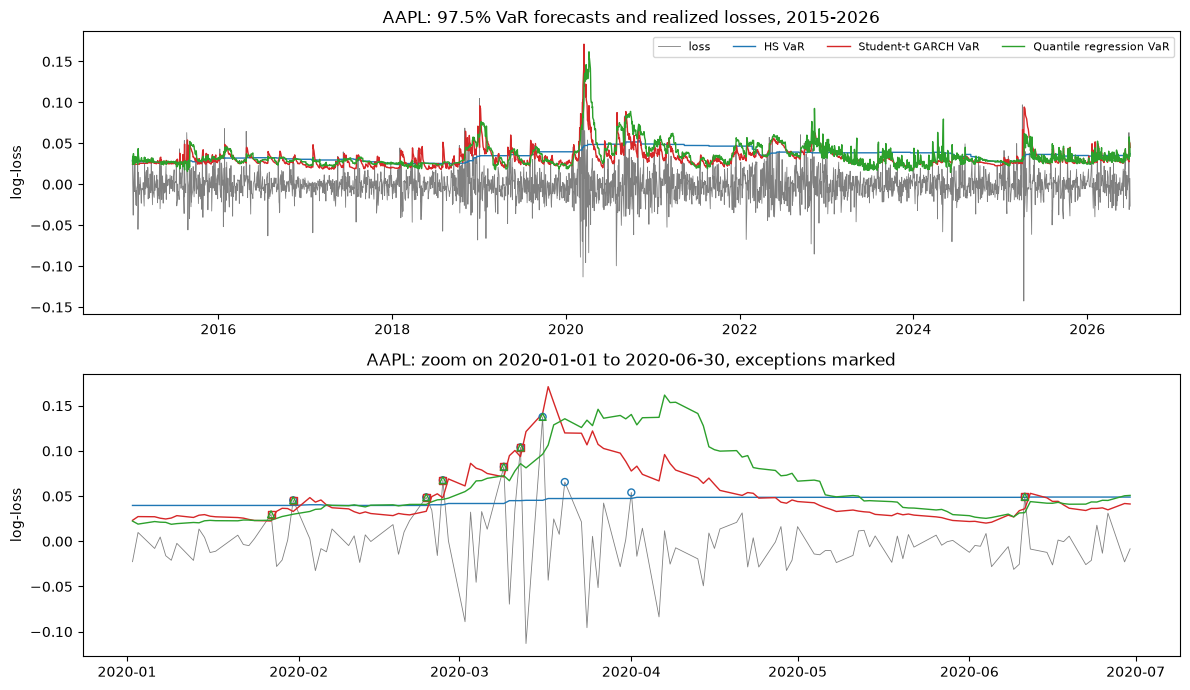

In [44]:
# Figure for Questions 4(d) and 5(b): AAPL 97.5% VaR forecasts of HS, Student-t GARCH and quantile regression
# against the realized losses; top: whole evaluation period, bottom: first half of 2020 with the exceptions marked
FIG_TIC, FIG_ALPHA = "AAPL", 0.975
ZOOM = ("2020-01-01", "2020-06-30")
FIG_METHODS = [("HS", "tab:blue", "o"), ("Student-t GARCH", "tab:red", "s"), (QR, "tab:green", "^")]

L = eval_loss[FIG_TIC]
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for ax, (start, end) in zip(axes, [(L.index[0], L.index[-1]), ZOOM]):
    Lz = L.loc[start:end]
    ax.plot(Lz.index, Lz, color="grey", lw=0.6, label="loss")
    for method, color, marker in FIG_METHODS:
        v = fc[FIG_TIC][f"{method}_VaR_{FIG_ALPHA}"].loc[start:end]
        ax.plot(v.index, v, color=color, lw=1, label=f"{method} VaR")
        if start == ZOOM[0]:
            hit = Lz > v
            ax.scatter(Lz.index[hit], Lz[hit], color=color, marker=marker, s=25, facecolors="none", zorder=3)
            print(f"{method}: {int(hit.sum())} exceptions in {len(Lz)} days ({len(Lz) * (1 - FIG_ALPHA):.1f} expected):",
                  ", ".join(Lz.index[hit].strftime("%m-%d")))
    ax.set_ylabel("log-loss")
axes[0].set_title(f"{FIG_TIC}: {FIG_ALPHA:.1%} VaR forecasts and realized losses, 2015-2026")
axes[1].set_title(f"{FIG_TIC}: zoom on {ZOOM[0]} to {ZOOM[1]}, exceptions marked")
axes[0].legend(fontsize=8, ncol=4, loc="upper right")
plt.tight_layout()
plt.savefig(OUT_DIR / "fig_q4_q5_var_paths.png", dpi=200)
plt.show()


### Question 5(c): model selection and validation

Discussion only, no code (report, Section 5.3).

## Question 6 -- Extreme value theory

One static fit on each stock's full-sample log-loss series, with threshold $u$ the empirical 95%
quantile. `scipy.stats.genpareto.fit(excesses, floc=0)` may be used for the GPD maximum-likelihood
step.

In [45]:
# Question 6 
from scipy.stats import genpareto

full_loss = losses                  # one column per stock
n = len(full_loss)                  # 3392
alpha = DEEP_ALPHA                  # 0.999
evt = {}                            # results for each stock, filled step by step

### Question 6 (b) 
Numbers section 6.2

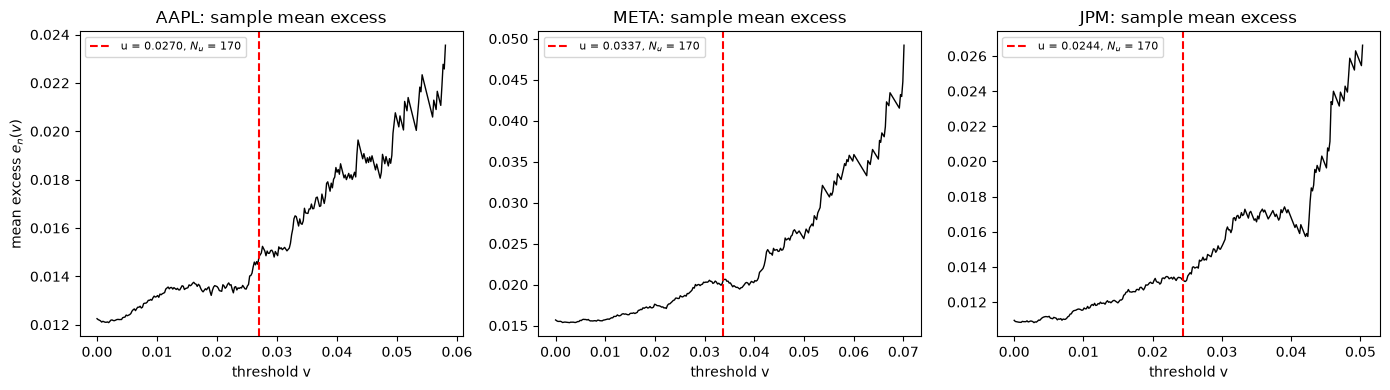

           u     Nu
AAPL  0.0270  170.0
META  0.0337  170.0
JPM   0.0244  170.0


In [46]:
# (b) 
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for i, tic in enumerate(TICKERS):
    L = full_loss[tic].values
    u = np.quantile(L, 0.95)                        
    Nu = np.sum(L > u)                             
    evt[tic] = {"u": u, "Nu": Nu}                   

    v_grid = np.linspace(0, np.sort(L)[-20], 300)
    mean_excess = [np.mean(L[L > v] - v) for v in v_grid]

    axes[i].plot(v_grid, mean_excess, color="black", lw=1)
    axes[i].axvline(u, color="red", ls="--", label=f"u = {u:.4f}, $N_u$ = {Nu}")
    axes[i].set_title(f"{tic}: sample mean excess")
    axes[i].set_xlabel("threshold v")
    axes[i].legend(fontsize=8)

axes[0].set_ylabel("mean excess $e_n(v)$")
plt.tight_layout()
plt.savefig(OUT_DIR / "fig_q6b_mean_excess.png", dpi=200)
plt.show()

print(pd.DataFrame(evt).T.round(4))

### Question 6 (c) 
section 6.3 numbers and figure 7

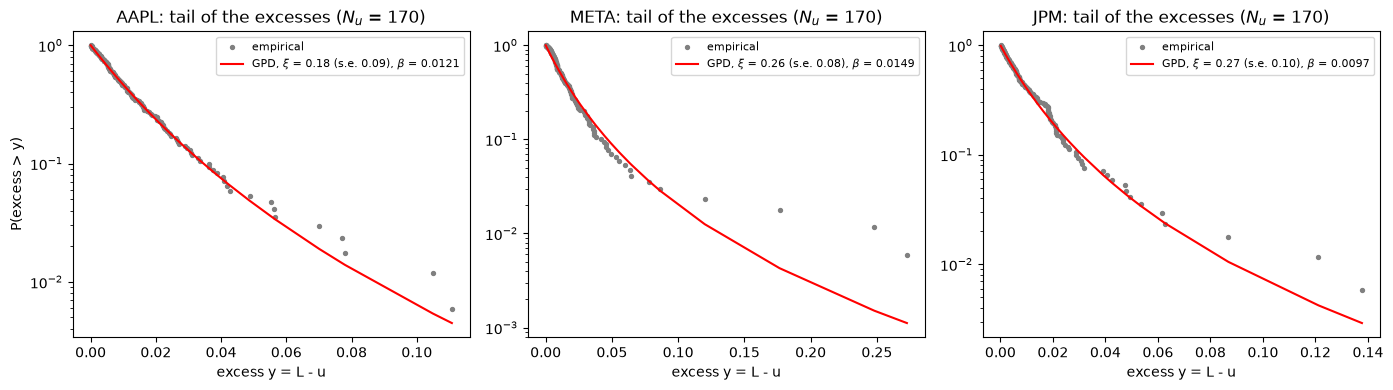

             u   Nu        xi    se(xi)      beta  se(beta)      1/xi E[L^4] finite
AAPL  0.026972  170  0.179218  0.090989  0.012131  0.001434  5.579809          True
META  0.033738  170  0.255755  0.079975   0.01488  0.001623  3.909985         False
JPM   0.024411  170  0.269358  0.096642  0.009702   0.00118  3.712532         False


In [47]:
# (c)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

def gpd_observed_information(excess, xi, beta):
    """J = -Hessian of the GPD log-likelihood at the estimate (observed Fisher information, Part VI p. 229)."""
    nll = lambda t: -genpareto.logpdf(excess, t[0], 0, t[1]).sum()
    theta = np.array([xi, beta])
    h = np.array([1e-4, 1e-4 * beta])          # finite-difference steps, scaled to each parameter
    J = np.zeros((2, 2))
    for a in range(2):
        for b in range(2):
            ea, eb = np.eye(2)[a] * h[a], np.eye(2)[b] * h[b]
            J[a, b] = (nll(theta + ea + eb) - nll(theta + ea - eb)
                       - nll(theta - ea + eb) + nll(theta - ea - eb)) / (4 * h[a] * h[b])
    return J

for i, tic in enumerate(TICKERS):
    L = full_loss[tic].values
    u = evt[tic]["u"]

    excess = L[L > u] - u
    Nu = len(excess)                             # same strict '>' as the excesses
    xi, loc, beta = genpareto.fit(excess, floc=0)

    # standard errors: square roots of the diagonal of J^{-1} (valid for xi > -1/2, Smith 1985)
    se_xi, se_beta = np.sqrt(np.diag(np.linalg.inv(gpd_observed_information(excess, xi, beta))))

    evt[tic].update({"Nu": Nu, "xi": xi, "se(xi)": se_xi, "beta": beta, "se(beta)": se_beta,
                     "1/xi": np.inf if xi <= 0 else 1 / xi,   # xi <= 0: all moments finite
                     "E[L^4] finite": xi < 0.25})

    y = np.sort(excess)
    empirical_tail = (Nu - np.arange(Nu)) / Nu
    axes[i].scatter(y, empirical_tail, s=8, color="grey", label="empirical")
    axes[i].plot(y, genpareto.sf(y, xi, 0, beta), color="red",
                 label=f"GPD, $\\xi$ = {xi:.2f} (s.e. {se_xi:.2f}), $\\beta$ = {beta:.4f}")
    axes[i].set_yscale("log")
    axes[i].set_title(f"{tic}: tail of the excesses ($N_u$ = {Nu})")
    axes[i].set_xlabel("excess y = L - u")
    axes[i].legend(fontsize=8)

axes[0].set_ylabel("P(excess > y)")
plt.tight_layout()
plt.savefig(OUT_DIR / "fig_q6c_gpd_fit.png", dpi=200)
plt.show()

print(pd.DataFrame(evt).T[["u", "Nu", "xi", "se(xi)", "beta", "se(beta)", "1/xi", "E[L^4] finite"]])

In [ ]:
# Question 6(c) - fit of the GPD over the gains to analyse the right tail of R
rows = []
for tic in TICKERS:
    for side, x in [("losses (left tail of R)", full_loss[tic].values),
                    ("gains (right tail of R)", returns[tic].values)]:
        u_s = np.quantile(x, 0.95)                     
        exc = x[x > u_s] - u_s                          
        xi_s, _, beta_s = genpareto.fit(exc, floc=0)    
        se_s = np.sqrt(np.linalg.inv(gpd_observed_information(exc, xi_s, beta_s))[0, 0])
        rows.append({"stock": tic, "tail": side, "Nu": len(exc),
                     "xi": xi_s, "se(xi)": se_s, "xi < 0.25": xi_s < 0.25})
print(pd.DataFrame(rows).set_index(["stock", "tail"]).round(3))

                                Nu     xi  se(xi)  xi < 0.25
stock tail                                                  
AAPL  losses (left tail of R)  170  0.179   0.091       True
      gains (right tail of R)  170  0.257   0.099      False
META  losses (left tail of R)  170  0.256   0.080      False
      gains (right tail of R)  170  0.405   0.107      False
JPM   losses (left tail of R)  170  0.269   0.097      False
      gains (right tail of R)  170  0.271   0.094      False


section 6.2 figure 6

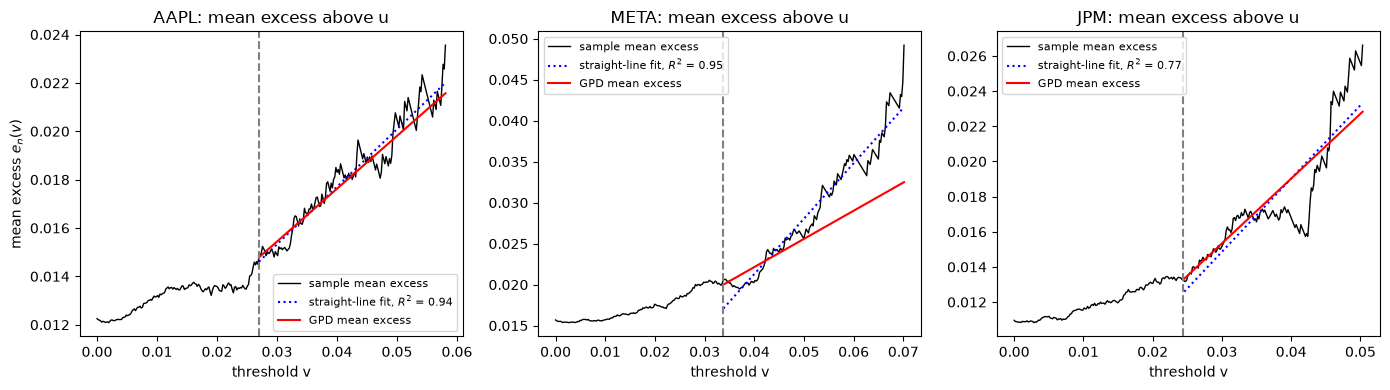

          R2  slope of fitted line  GPD slope xi/(1-xi)
stock                                                  
AAPL   0.945                 0.238                0.218
META   0.954                 0.676                0.344
JPM    0.774                 0.417                0.369


In [49]:
# Question 6 (b) check
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
rows = []

for i, tic in enumerate(TICKERS):
    L = full_loss[tic].values
    u, xi, beta = evt[tic]["u"], evt[tic]["xi"], evt[tic]["beta"]

    # sample mean excess, up to the 20th largest loss
    v_grid = np.linspace(0, np.sort(L)[-20], 300)
    mean_excess = np.array([np.mean(L[L > v] - v) for v in v_grid])

    # keep only the part above u
    above = v_grid >= u
    v_above = v_grid[above]
    me_above = mean_excess[above]

    # argument 1: best straight line and its R^2
    slope, intercept = np.polyfit(v_above, me_above, 1)
    line = intercept + slope * v_above
    r2 = 1 - np.sum((me_above - line) ** 2) / np.sum((me_above - me_above.mean()) ** 2)

    # argument 2: the straight line implied by the fitted GPD
    gpd_line = (beta + xi * (v_above - u)) / (1 - xi)

    axes[i].plot(v_grid, mean_excess, color="black", lw=1, label="sample mean excess")
    axes[i].plot(v_above, line, color="blue", ls=":", label=f"straight-line fit, $R^2$ = {r2:.2f}")
    axes[i].plot(v_above, gpd_line, color="red", label="GPD mean excess")
    axes[i].axvline(u, color="grey", ls="--")
    axes[i].set_title(f"{tic}: mean excess above u")
    axes[i].set_xlabel("threshold v")
    axes[i].legend(fontsize=8)

    rows.append({"stock": tic, "R2": r2,
                 "slope of fitted line": slope,
                 "GPD slope xi/(1-xi)": xi / (1 - xi)})

axes[0].set_ylabel("mean excess $e_n(v)$")
plt.tight_layout()
plt.savefig(OUT_DIR / "fig_q6b_linearity.png", dpi=200)
plt.show()

print(pd.DataFrame(rows).set_index("stock").round(3))

### Question 6 (d) 
section 6.4

In [50]:
# (d)
ALPHA_EVT = 0.999                                   
for tic in TICKERS:
    n = full_loss[tic].dropna().shape[0]            
    u, Nu, xi, beta = evt[tic]["u"], evt[tic]["Nu"], evt[tic]["xi"], evt[tic]["beta"]
    var_gpd = u + beta / xi * ((n * (1 - ALPHA_EVT) / Nu) ** (-xi) - 1)   # invert the tail estimate
    es_gpd = var_gpd / (1 - xi) + (beta - xi * u) / (1 - xi)             # VaR + e(VaR)
    evt[tic].update({"n": n, "VaR_GPD": var_gpd, "ES_GPD": es_gpd,
                     "HS exceedances n(1-alpha)": n * (1 - ALPHA_EVT)})

print(pd.DataFrame(evt).T[["n", "Nu", "HS exceedances n(1-alpha)"]].astype(float).round(2))
print(pd.DataFrame(evt).T[["VaR_GPD", "ES_GPD"]].astype(float).mul(100).round(2))   # in %

           n     Nu  HS exceedances n(1-alpha)
AAPL  3392.0  170.0                       3.39
META  3392.0  170.0                       3.39
JPM   3392.0  170.0                       3.39
      VaR_GPD  ES_GPD
AAPL     9.58   12.56
META    13.39   18.83
JPM      9.18   12.99


### Question 6 (e) 
section 6 table 16

In [51]:
# Question 6 (e)
rows = []
for tic in TICKERS:
    L = full_loss[tic].values
    var_gpd, es_gpd = evt[tic]["VaR_GPD"], evt[tic]["ES_GPD"]

    var_n, es_n = normal_var_es(L.mean(), L.std(ddof=1), ALPHA_EVT)
    nu, mu_t, sigma_t, loglik = fit_t(L)
    var_t, es_t = t_var_es(nu, mu_t, sigma_t, ALPHA_EVT)
    print(f"{tic}: Student nu = {nu:.2f}, 1/nu = {1/nu:.3f}, GPD xi = {evt[tic]['xi']:.3f}")

    for method, var, es in [("GPD", var_gpd, es_gpd),
                            ("Gaussian", var_n, es_n),
                            ("Student-t", var_t, es_t)]:
        rows.append({"stock": tic, "method": method,
                     "VaR (%)": 100 * var, "ES (%)": 100 * es,
                     "VaR vs GPD (%)": 100 * (var / var_gpd - 1),
                     "ES vs GPD (%)": 100 * (es / es_gpd - 1)})

q6_table = pd.DataFrame(rows).set_index(["stock", "method"])
print(q6_table.round(2))

AAPL: Student nu = 3.28, 1/nu = 0.305, GPD xi = 0.179
META: Student nu = 3.15, 1/nu = 0.318, GPD xi = 0.256
JPM: Student nu = 3.20, 1/nu = 0.313, GPD xi = 0.269
                 VaR (%)  ES (%)  VaR vs GPD (%)  ES vs GPD (%)
stock method                                                   
AAPL  GPD           9.58   12.56            0.00           0.00
      Gaussian      5.41    5.91          -43.49         -52.98
      Student-t    10.42   15.17            8.82          20.77
META  GPD          13.39   18.83            0.00           0.00
      Gaussian      7.35    8.02          -45.07         -57.40
      Student-t    13.71   20.27            2.37           7.65
JPM   GPD           9.18   12.99            0.00           0.00
      Gaussian      4.97    5.42          -45.81         -58.24
      Student-t     9.48   13.93            3.29           7.24
